# **2. Mapa Semântico dos Motivos de Cartão**

Este notebook implementa a análise semântica dos motivos de cartão usando a base limpa gerada pelo notebook 1.

Responsabilidade deste notebook:

- carregar `data/processed/card_reasons_long.csv`;
- transformar os motivos limpos em embeddings;
- clusterizar motivos semanticamente parecidos;
- projetar o mapa semântico em 2D;
- gerar tabelas de interpretação por cluster, ano, time e árbitro.

## **1. Configuração**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 180)
plt.style.use("seaborn-v0_8-whitegrid")

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
OUTPUT_DIR = PROCESSED_PATH / "semantic_card_reasons"

CARD_REASONS_LONG_PATH = PROCESSED_PATH / "card_reasons_long.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
TEXT_COLUMN = "reason_detail_key"

## **2. Carregamento da Base Limpa**

A entrada deste notebook é `card_reasons_long.csv`, criada no notebook 1. Cada linha representa um cartão e já contém o texto limpo do motivo.

A coluna principal para embedding é `reason_detail_key`, que reduz o peso de prefixos burocráticos como “Outro motivo...”. Quando a descrição livre não existe, o notebook 1 preenche essa coluna com a categoria limpa.

In [3]:
REQUIRED_COLUMNS = {
    "year",
    "match_date",
    "home_team",
    "away_team",
    "arbitro",
    "card_type",
    "team",
    "reason",
    "reason_key",
    "reason_category",
    "reason_category_key",
    "reason_detail",
    "reason_detail_key",
}

reasons = pd.read_csv(CARD_REASONS_LONG_PATH)
missing = REQUIRED_COLUMNS.difference(reasons.columns)
if missing:
    raise ValueError(f"Colunas ausentes em card_reasons_long.csv: {sorted(missing)}")

reasons[TEXT_COLUMN] = reasons[TEXT_COLUMN].fillna("").astype(str).str.strip()
reasons = reasons[reasons[TEXT_COLUMN].ne("")].reset_index(drop=True)
reasons.head()

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,reason_category,reason_category_key,reason_detail,reason_detail_key
0,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar ostensivamente com palavras e gestos.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem. - por reclamar ostensivamente com palavras e gestos.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem.,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.
1,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,37,1T,Cometer uma falta tática para impedir um ataque promissor - Calçar o adversário disputando a bola e impedir um ataque promissor .,cometer uma falta tatica para impedir um ataque promissor - calcar o adversario disputando a bola e impedir um ataque promissor .,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Calçar o adversário disputando a bola e impedir um ataque promissor .,calcar o adversario disputando a bola e impedir um ataque promissor .
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,18,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de maneira temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar um calco em seu adversario na disputa pela bola de maneira temeraria.
3,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,28,2T,"Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) - Por cometer uma atitude antidesportiva fora da disputa pela bola.","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser) - por cometer uma atitude antidesportiva fora da disputa pela bola.","Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser)","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser)",Por cometer uma atitude antidesportiva fora da disputa pela bola.,por cometer uma atitude antidesportiva fora da disputa pela bola.
4,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,28,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de forma temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar um calco em seu adversario na disputa pela bola de forma temeraria.


## **3. Preparação dos Textos para Embedding**

Para não deixar frases repetidas dominarem o mapa, os embeddings são calculados sobre os textos únicos de `reason_detail_key`. Depois os clusters são propagados de volta para todos os cartões.

In [4]:
reason_counts = reasons.groupby(TEXT_COLUMN).agg(
    reason=("reason", "first"),
    reason_category=("reason_category", "first"),
    reason_detail=("reason_detail", "first"),
    n_events=("reason", "size"),
    n_yellow=("card_type", lambda values: (values == "yellow").sum()),
    n_red=("card_type", lambda values: (values == "red").sum()),
).reset_index().rename(columns={TEXT_COLUMN: "embedding_key"})

reason_counts["text_for_embedding"] = reason_counts["embedding_key"]
reason_counts = reason_counts.sort_values("n_events", ascending=False).reset_index(drop=True)
reason_counts.head(15)

,embedding_key,reason,reason_category,reason_detail,n_events,n_yellow,n_red,text_for_embedding
0,por calcar seu adversario de maneira temeraria na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de maneira temerária na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,Por calçar seu adversário de maneira temerária na disputa de bola.,238,238,0,por calcar seu adversario de maneira temeraria na disputa de bola.
1,por cometer uma falta tatica impedindo um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática impedindo um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,Por cometer uma falta tática impedindo um ataque promissor.,154,154,0,por cometer uma falta tatica impedindo um ataque promissor.
2,cometer uma falta tatica para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Cometer uma falta tática para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,125,124,1,cometer uma falta tatica para impedir um ataque promissor.
3,por retardar o reinicio de jogo.,Retardar o reinício do jogo - Por retardar o reinício de jogo.,Retardar o reinício do jogo,Por retardar o reinício de jogo.,122,122,0,por retardar o reinicio de jogo.
4,por cometer uma falta tatica para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática para impedir um ataque promissor.,Cometer uma falta tática para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,115,115,0,por cometer uma falta tatica para impedir um ataque promissor.
5,dar uma entrada contra um adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,104,103,1,dar uma entrada contra um adversario de maneira temeraria na disputa da bola.
6,por dar uma entrada contra seu adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.,103,103,0,por dar uma entrada contra seu adversario de maneira temeraria na disputa da bola.
7,por calcar seu adversario de forma temeraria na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de forma temerária na disputa de bola.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,Por calçar seu adversário de forma temerária na disputa de bola.,91,91,0,por calcar seu adversario de forma temeraria na disputa de bola.
8,dar uma entrada contra um adversario de maneira temeraria na disputa de bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Dar uma entrada contra um adversário de maneira temerária na disputa de bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa de bola.,87,87,0,dar uma entrada contra um adversario de maneira temeraria na disputa de bola.
9,por dar uma entrada contra um adversario de maneira temeraria na disputa da bola.,Dar uma entrada contra um adversário de maneira temerária na disputa da bola - Por dar um

In [5]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "adversario", "adversaria", "jogador", "maneira", "bola", "disputa", "dar", "tentar", "seu", "sua",
}


def build_tfidf_matrix(texts: pd.Series):
    vectorizer = TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.95,
        stop_words=list(PORTUGUESE_STOPWORDS),
    )
    matrix = vectorizer.fit_transform(texts)
    return vectorizer, matrix

## **4. Embeddings Textuais**

O backend usa `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, um encoder multilíngue adequado para frases curtas em português.

In [6]:
texts = reason_counts["text_for_embedding"].tolist()
embedding_model = SentenceTransformer(MODEL_NAME)
embeddings = embedding_model.encode(
    texts,
    show_progress_bar=False,
    normalize_embeddings=True,
)
embeddings = np.asarray(embeddings)
EMBEDDING_BACKEND = "sentence-transformers"

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7173.94it/s]


## **5. Escolha do Número de Clusters**

A célula abaixo testa valores de `k` com silhouette score. O valor escolhido automaticamente é o melhor score dentro do intervalo, mas você pode sobrescrever `BEST_K` manualmente antes de rodar a clusterização.

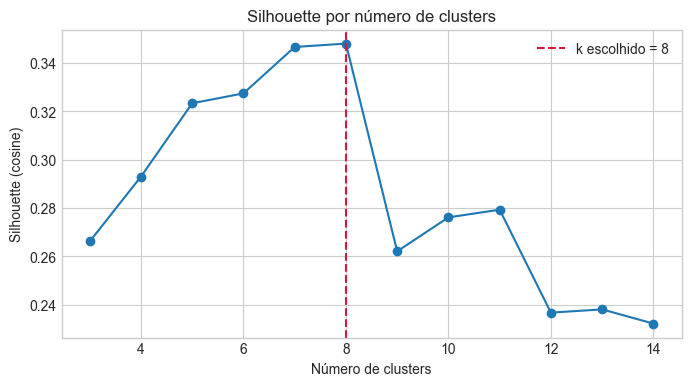

,k,silhouette
0,3,0.266205
1,4,0.292999
2,5,0.323285
3,6,0.327371
4,7,0.346540
5,8,0.347941
6,9,0.262128
7,10,0.276152
8,11,0.279339
9,12,0.236819


In [7]:
max_k = min(14, len(reason_counts) - 1)
candidate_ks = list(range(3, max_k + 1))
scores = []

for k in candidate_ks:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=25).fit_predict(embeddings)
    score = silhouette_score(embeddings, labels, metric="cosine")
    scores.append({"k": k, "silhouette": score})

cluster_scores = pd.DataFrame(scores)
BEST_K = int(cluster_scores.sort_values("silhouette", ascending=False).iloc[0]["k"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cluster_scores["k"], cluster_scores["silhouette"], marker="o")
ax.axvline(BEST_K, color="crimson", linestyle="--", label=f"k escolhido = {BEST_K}")
ax.set_title("Silhouette por número de clusters")
ax.set_xlabel("Número de clusters")
ax.set_ylabel("Silhouette (cosine)")
ax.legend()
plt.show()

cluster_scores

In [8]:
cluster_model = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=50)
reason_counts["cluster"] = cluster_model.fit_predict(embeddings)

reasons_clustered = reasons.merge(
    reason_counts[["embedding_key", "cluster"]],
    left_on=TEXT_COLUMN,
    right_on="embedding_key",
    how="left",
).drop(columns=["embedding_key"])

reasons_clustered.head()

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,reason_category,reason_category_key,reason_detail,reason_detail_key,cluster
0,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar ostensivamente com palavras e gestos.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem. - por reclamar ostensivamente com palavras e gestos.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisao da arbitragem.,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.,5
1,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,37,1T,Cometer uma falta tática para impedir um ataque promissor - Calçar o adversário disputando a bola e impedir um ataque promissor .,cometer uma falta tatica para impedir um ataque promissor - calcar o adversario disputando a bola e impedir um ataque promissor .,Cometer uma falta tática para impedir um ataque promissor,cometer uma falta tatica para impedir um ataque promissor,Calçar o adversário disputando a bola e impedir um ataque promissor .,calcar o adversario disputando a bola e impedir um ataque promissor .,0
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,18,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de maneira temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de maneira temerária.,dar um calco em seu adversario na disputa pela bola de maneira temeraria.,0
3,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,28,2T,"Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser) - Por cometer uma atitude antidesportiva fora da disputa pela bola.","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser) - por cometer uma atitude antidesportiva fora da disputa pela bola.","Outro motivo (somente neste caso, abriria um campo livre para o árbitro digitar o que quiser)","outro motivo (somente neste caso, abriria um campo livre para o arbitro digitar o que quiser)",Por cometer uma atitude antidesportiva fora da disputa pela bola.,por cometer uma atitude antidesportiva fora da disputa pela bola.,0
4,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Flamengo,28,2T,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola - dar um calco em seu adversario na disputa pela bola de forma temeraria.,Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola,dar ou tentar dar uma rasteira ou um calco em um adversario de maneira temeraria na disputa da bola,Dar um calço em seu adversário na disputa pela bola de forma temerária.,dar um calco em seu adversario na disputa pela bola de forma temeraria.,0


## **6. Resumo Interpretável dos Clusters**

Para nomear os grupos, usamos duas pistas:

1. exemplos mais frequentes de cada cluster;
2. termos e bigramas com maior TF-IDF dentro do cluster.

O nome final do cluster deve ser refinado manualmente depois de inspecionar a tabela.

In [9]:
def top_terms_by_cluster(reason_table: pd.DataFrame, top_n: int = 8) -> pd.DataFrame:
    vectorizer_local, matrix = build_tfidf_matrix(reason_table["text_for_embedding"])
    feature_names = np.array(vectorizer_local.get_feature_names_out())
    rows = []
    for cluster_id, positions in reason_table.groupby("cluster").groups.items():
        cluster_matrix = matrix[list(positions)]
        weights = np.asarray(cluster_matrix.mean(axis=0)).ravel()
        top_positions = weights.argsort()[::-1][:top_n]
        rows.append({
            "cluster": cluster_id,
            "top_terms": ", ".join(feature_names[top_positions]),
        })
    return pd.DataFrame(rows)


def top_examples_by_cluster(reason_table: pd.DataFrame, top_n: int = 4) -> pd.DataFrame:
    rows = []
    for cluster_id, group in reason_table.groupby("cluster"):
        examples = (
            group.sort_values("n_events", ascending=False)
            .head(top_n)["reason"]
            .tolist()
        )
        rows.append({
            "cluster": cluster_id,
            "top_examples": " | ".join(examples),
        })
    return pd.DataFrame(rows)

cluster_terms = top_terms_by_cluster(reason_counts)
cluster_examples = top_examples_by_cluster(reason_counts)

cluster_summary = reason_counts.groupby("cluster").agg(
    n_unique_texts=("embedding_key", "size"),
    n_card_events=("n_events", "sum"),
    yellow_events=("n_yellow", "sum"),
    red_events=("n_red", "sum"),
).reset_index()
cluster_summary["red_pct"] = cluster_summary["red_events"] / cluster_summary["n_card_events"]
cluster_summary = (
    cluster_summary
    .merge(cluster_terms, on="cluster", how="left")
    .merge(cluster_examples, on="cluster", how="left")
    .sort_values("n_card_events", ascending=False)
    .reset_index(drop=True)
)

cluster_summary

,cluster,n_unique_texts,n_card_events,yellow_events,red_events,red_pct,top_terms,top_examples
0,0,1705,4941,4900,41,0.008298,"temeraria, entrada, entrada temeraria, forma temeraria, forma, calcar, golpear, calco",Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de maneira temerária na disputa de bola. | Dar u...
1,1,699,1743,1722,21,0.012048,"arbitragem, decisoes, decisoes arbitragem, reclamar, contra, contra decisoes, desaprovar, palavras",Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar das decisões da arbitragem. | Reclamar / protestar (verb...
2,2,322,1273,1267,6,0.004713,"ataque, promissor, ataque promissor, impedindo ataque, impedindo, impedir ataque, impedir, tatica",Cometer uma falta tática para impedir um ataque promissor - Por cometer uma falta tática impedindo um ataque promissor. | Cometer uma falta tática para impedir um ataque promis...
3,6,570,920,908,12,0.013043,"jogo, desrespeito, desrespeito jogo, antidesportiva, mostrando, mostrando desrespeito, conduta, conduta antidesportiva",Infringir persistentemente as regras do jogo - Por infringir persistentemente as regras do jogo. | Atuar de maneira a mostrar desrespeito ao jogo - Atuar de maneira a mostrar d...
4,5,420,779,762,17,0.021823,"temeraria, entrada, forma temeraria, forma, calcar, entrada temeraria, braco, golpear",Dar ou tentar dar uma rasteira ou um calço em um adversário de maneira temerária na disputa da bola - Por calçar seu adversário de maneira temerária. | Dar ou tentar dar uma ra...
5,3,327,665,658,7,0.010526,"retardar, reinicio, reinicio jogo, retardar reinicio, jogo, tiro, cobranca, substituicao",Retardar o reinício do jogo - Por retardar o reinício de jogo. | Retardar o reinício do jogo - Por retardar o reinicio do jogo. | Retardar o reinício do jogo - Retardar o reiní...
6,7,473,478,77,401,0.838912,"atleta, equipe, sr, expulsei, campo, cartao, expulso, apos",Infringir persistentemente as regras do jogo - Por rodizio de faltas da equipe. | Outro motivo (detalhar no campo expulsões) - Expulso por ir em direção ao banco de reserva da ...
7,4,141,164,161,3,0.018293,"gol, comemoracao, comemoracao gol, camisa, tirar, tirar camisa, gol equipe, comemorar",Tirar a camisa por cima de sua cabeça ou cobri-la com a camisa - Por tirar a camisa na comemoração do gol. | Comemoração de um gol - Por tirar a camisa na comemoração de um gol...


## **7. Projeção 2D: Mapa Semântico**

A projeção 2D reduz os embeddings para duas dimensões. Pontos próximos representam motivos semanticamente parecidos. O tamanho do ponto indica quantas vezes aquele texto apareceu nas súmulas.

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


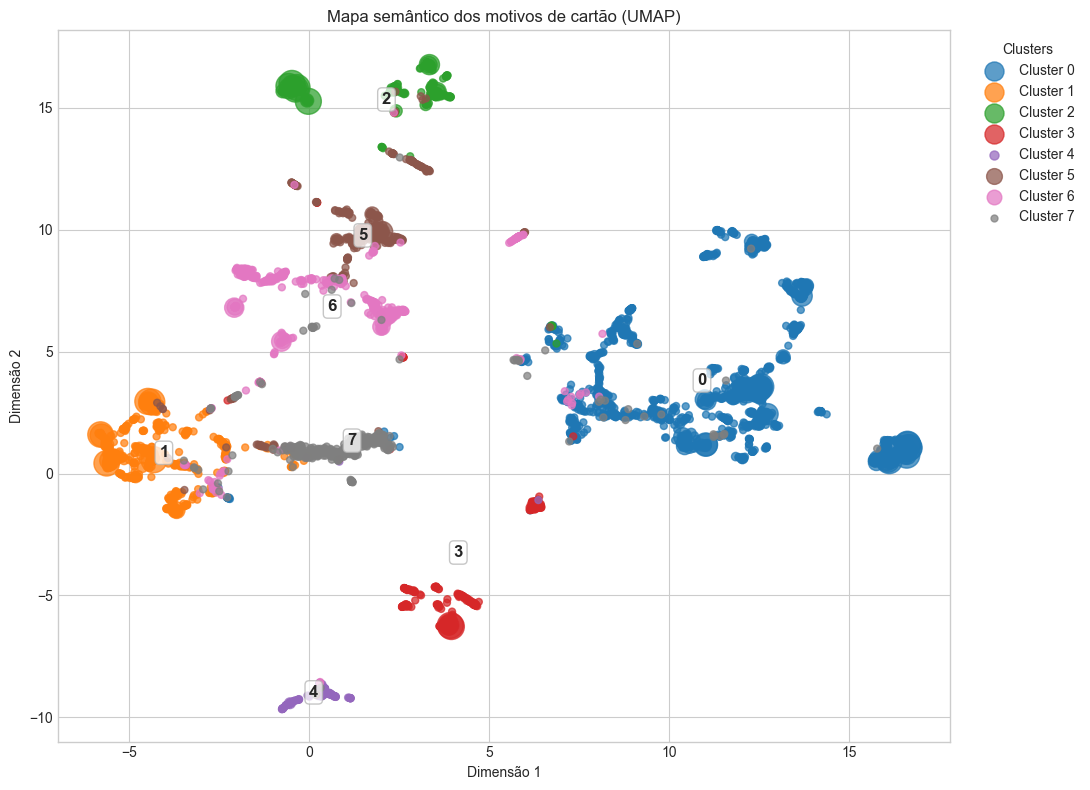

In [10]:
reducer = umap.UMAP(
    n_neighbors=min(15, len(reason_counts) - 1),
    min_dist=0.08,
    metric="cosine",
    random_state=RANDOM_STATE,
)
coords = reducer.fit_transform(embeddings)
projection_method = "UMAP"

reason_counts["x"] = coords[:, 0]
reason_counts["y"] = coords[:, 1]

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id, group in reason_counts.groupby("cluster"):
    ax.scatter(
        group["x"],
        group["y"],
        s=np.clip(group["n_events"] * 6, 25, 350),
        alpha=0.72,
        label=f"Cluster {cluster_id}",
    )

for cluster_id, group in reason_counts.groupby("cluster"):
    centroid = group[["x", "y"]].mean()
    ax.text(
        centroid["x"],
        centroid["y"],
        str(cluster_id),
        fontsize=12,
        fontweight="bold",
        ha="center",
        va="center",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "0.7"},
    )

ax.set_title(f"Mapa semântico dos motivos de cartão ({projection_method})")
ax.set_xlabel("Dimensão 1")
ax.set_ylabel("Dimensão 2")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters")
plt.tight_layout()
plt.show()

In [11]:
fig_path = OUTPUT_DIR / "card_reason_semantic_map.png"

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id, group in reason_counts.groupby("cluster"):
    ax.scatter(
        group["x"],
        group["y"],
        s=np.clip(group["n_events"] * 6, 25, 350),
        alpha=0.72,
        label=f"Cluster {cluster_id}",
    )
for cluster_id, group in reason_counts.groupby("cluster"):
    centroid = group[["x", "y"]].mean()
    ax.text(
        centroid["x"],
        centroid["y"],
        str(cluster_id),
        fontsize=12,
        fontweight="bold",
        ha="center",
        va="center",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "0.7"},
    )
ax.set_title(f"Mapa semântico dos motivos de cartão ({projection_method})")
ax.set_xlabel("Dimensão 1")
ax.set_ylabel("Dimensão 2")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Clusters")
plt.tight_layout()
fig.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.close(fig)
fig_path

PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_semantic_map.png')

## **8. Leituras por Ano, Time e Árbitro**

Depois de rotular cada cartão com um cluster semântico, dá para comparar a distribuição dos tipos de punição por ano, time e árbitro.

In [12]:
cluster_by_year = pd.crosstab(
    reasons_clustered["year"],
    reasons_clustered["cluster"],
    normalize="index",
).round(3)

cluster_by_year

cluster,0,1,2,3,4,5,6,7
year,,,,,,,,
2020,0.483,0.143,0.100,0.040,0.008,0.124,0.049,0.054
2021,0.470,0.163,0.082,0.056,0.020,0.083,0.084,0.042
2022,0.444,0.172,0.094,0.059,0.015,0.075,0.097,0.044
2023,0.444,0.163,0.117,0.066,0.016,0.061,0.094,0.038
2024,0.407,0.175,0.138,0.083,0.014,0.052,0.088,0.043
2025,0.468,0.136,0.155,0.055,0.019,0.040,0.084,0.043
2026,0.435,0.161,0.134,0.061,0.010,0.064,0.094,0.041


In [13]:
top_teams = reasons_clustered["team"].value_counts().head(12).index
cluster_by_team = pd.crosstab(
    reasons_clustered[reasons_clustered["team"].isin(top_teams)]["team"],
    reasons_clustered[reasons_clustered["team"].isin(top_teams)]["cluster"],
    normalize="index",
).round(3)

cluster_by_team

cluster,0,1,2,3,4,5,6,7
team,,,,,,,,
Athletico Paranaense,0.449,0.128,0.123,0.081,0.015,0.059,0.095,0.048
Atlético Mineiro,0.436,0.141,0.128,0.068,0.015,0.073,0.096,0.043
Corinthians,0.407,0.159,0.113,0.046,0.021,0.123,0.077,0.054
Flamengo,0.479,0.132,0.108,0.035,0.024,0.097,0.082,0.043
Fluminense,0.470,0.176,0.094,0.073,0.016,0.062,0.074,0.034
Fortaleza Esporte Clube,0.432,0.163,0.109,0.068,0.009,0.090,0.072,0.057
Grêmio,0.434,0.170,0.146,0.082,0.007,0.040,0.077,0.044
Internacional,0.440,0.178,0.122,0.072,0.013,0.070,0.075,0.031
Palmeiras,0.402,0.188,0.124,0.049,0.021,0.084,0.094,0.039


In [14]:
top_referees = reasons_clustered["arbitro"].value_counts().head(12).index
cluster_by_referee = pd.crosstab(
    reasons_clustered[reasons_clustered["arbitro"].isin(top_referees)]["arbitro"],
    reasons_clustered[reasons_clustered["arbitro"].isin(top_referees)]["cluster"],
    normalize="index",
).round(3)

cluster_by_referee

cluster,0,1,2,3,4,5,6,7
arbitro,,,,,,,,
Anderson Daronco,0.495,0.119,0.150,0.050,0.013,0.096,0.044,0.033
Braulio da Silva Machado,0.489,0.205,0.073,0.044,0.015,0.032,0.110,0.032
Bruno Arleu de Araujo,0.527,0.112,0.104,0.059,0.012,0.066,0.076,0.045
Felipe Fernandes de Lima,0.401,0.169,0.106,0.050,0.005,0.103,0.119,0.047
Flavio Rodrigues de Souza,0.426,0.157,0.151,0.055,0.023,0.066,0.085,0.038
Rafael Rodrigo Klein,0.449,0.185,0.102,0.086,0.016,0.039,0.063,0.060
Ramon Abatti Abel,0.438,0.147,0.118,0.062,0.018,0.100,0.091,0.027
Raphael Claus,0.464,0.095,0.137,0.046,0.006,0.114,0.103,0.035
Rodrigo Jose Pereira de Lima,0.459,0.179,0.158,0.047,0.018,0.039,0.060,0.041


## **9. Busca Semântica de Motivos Parecidos**

Esta função consulta o espaço vetorial. Exemplos úteis:

- `semantic_search("reclamação contra arbitragem")`
- `semantic_search("entrada temerária na disputa de bola")`
- `semantic_search("retardar o reinício do jogo")`
- `semantic_search("conduta violenta")`

In [15]:
def embed_query(texts_to_embed: list[str]) -> np.ndarray:
    return np.asarray(embedding_model.encode(texts_to_embed, normalize_embeddings=True))


def semantic_search(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query([query])
    similarities = cosine_similarity(query_embedding, embeddings).ravel()
    result = reason_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "cluster",
        "similarity",
        "n_events",
        "n_yellow",
        "n_red",
        "reason_category",
        "reason_detail",
        "reason",
    ]].head(top_k)

semantic_search("reclamação contra arbitragem", top_k=10)

,cluster,similarity,n_events,n_yellow,n_red,reason_category,reason_detail,reason
2216,1,0.912356,1,1,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Por reclamar contra a arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamar contra a arbitragem.
2186,1,0.911331,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamacao contra arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamacao contra arbitragem.
708,1,0.906351,2,2,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Por reclamação contra à arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Por reclamação contra à arbitragem.
849,1,0.895261,2,2,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Reclamação contra a arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Reclamação contra a arbitragem.
2272,1,0.894571,1,1,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar da marcação da arbitragem,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar da marcação da arbitragem
84,1,0.892226,15,15,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Reclamar contra as decisões da arbitragem,Desaprovar com palavras ou gestos as decisões da arbitragem - Reclamar contra as decisões da arbitragem
235,1,0.891614,6,6,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Reclamar contra a decisão da arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Reclamar contra a decisão da arbitragem.
2049,1,0.889928,1,1,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Reclamar das marcações da arbitragem,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Reclamar das marcações da arbitragem
2043,1,0.888474,1,1,0,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem.,Reclamar contra as marcações da arbitragem.,Reclamar / protestar (verbalmente ou por gestos) ostensiva e ofensivamente contra decisão da arbitragem. - Reclamar contra as marcações da arbitragem.
729,1,0.881012,2,2,0,Desaprovar com palavras ou gestos as decisões da arbitragem,Por reclamar contra a decisão da arbitragem.,Desaprovar com palavras ou gestos as decisões da arbitragem - Por reclamar contra a decisão da arbitragem.


## **10. Salvamento dos Artefatos**

In [16]:
reason_counts_path = OUTPUT_DIR / "card_reason_unique_clusters.csv"
reasons_clustered_path = OUTPUT_DIR / "card_reasons_long_with_clusters.csv"
cluster_summary_path = OUTPUT_DIR / "card_reason_cluster_summary.csv"
cluster_by_year_path = OUTPUT_DIR / "card_reason_clusters_by_year.csv"
cluster_by_team_path = OUTPUT_DIR / "card_reason_clusters_by_team_top12.csv"
cluster_by_referee_path = OUTPUT_DIR / "card_reason_clusters_by_referee_top12.csv"

reason_counts.to_csv(reason_counts_path, index=False)
reasons_clustered.to_csv(reasons_clustered_path, index=False)
cluster_summary.to_csv(cluster_summary_path, index=False)
cluster_by_year.to_csv(cluster_by_year_path)
cluster_by_team.to_csv(cluster_by_team_path)
cluster_by_referee.to_csv(cluster_by_referee_path)

[
    reason_counts_path,
    reasons_clustered_path,
    cluster_summary_path,
    cluster_by_year_path,
    cluster_by_team_path,
    cluster_by_referee_path,
    fig_path,
]

[PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_unique_clusters.csv'),
 PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reasons_long_with_clusters.csv'),
 PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_cluster_summary.csv'),
 PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_clusters_by_year.csv'),
 PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_clusters_by_team_top12.csv'),
 PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_clusters_by_referee_top12.csv'),
 PosixPath('/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_card_reasons/card_reason_semanti

## **11. Próximos Passos Analíticos**

Depois de rodar o notebook, revise `cluster_summary` e dê nomes substantivos aos clusters, por exemplo:

- falta temerária;
- reclamação/protesto;
- retardar reinício;
- impedir ataque promissor;
- conduta violenta;
- segundo amarelo/expulsão.

Esses nomes podem virar uma coluna manual `cluster_label`, útil para gráficos finais e para transformar o mapa semântico em uma análise disciplinar interpretável.